# Frozen Toto 2.0 forecast-error detector

Toto forecasts the last 32 measurements of each window from the first 96. A large normalized forecast error suggests a fault. Channel scales come from normal training windows; the threshold is chosen on development data only. A last-value forecast uses the same scales and threshold rule as a simple reference.

The release has unresolved recording reviews, so these results are provisional. Threshold selection uses labels, so the detector is not fully unsupervised. It does not predict fault categories.

Command-line equivalent: `uv run --python 3.12 python -m clauseguard.cli.toto train --release-dir data/scenarios/release --xgboost-reference artifacts/experiments/xgboost-full-data-2026-10-19 --output-dir artifacts/experiments/toto-detection-2026-11-05 --allow-exploratory`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from clauseguard.baselines.artifacts import load_run
from clauseguard.baselines.tree_data import split_data
from clauseguard.datasets.contracts import NUMERIC_CHANNELS
from clauseguard.datasets.scenarios import ScenarioDataset
from clauseguard.kpi.toto import CONTEXT, HORIZON, QUANTILES, fill_context, load_forecaster, split_windows, window_arrays

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "data/scenarios/release/release.json").exists())
os.chdir(ROOT)
OUTPUT_DIR = Path("artifacts/experiments/toto-detection-2026-11-05")
SUMMARY = json.loads((OUTPUT_DIR / "selection.json").read_text())
DATASET = ScenarioDataset(Path("data/scenarios/release"), allow_exploratory=True)
pd.DataFrame(SUMMARY["detectors"]).T[["macro_f1", "recall", "false_alarms", "missed_faults", "failed_predictions"]]

,macro_f1,recall,false_alarms,missed_faults,failed_predictions
last_value,0.532693,0.085502,175,246,0
toto,0.561048,0.156134,222,227,0


## Compare with XGBoost on the same development windows

All three runs score the identical dev cohort. Failed forecasts stay in the denominator.

In [2]:
rows = []
for name, run in SUMMARY["comparison"]["runs"].items():
    metrics = run["metrics"]
    rows.append({"model": name, "macro-F1": metrics["macro_f1"], "fault recall": metrics["recall"],
                 "false alarms": metrics["false_alarms"], "missed faults": metrics["missed_faults"],
                 "failed": sum(v for k, v in metrics["prediction_status_counts"].items() if k != "ok")})
pd.DataFrame(rows).round(3)

,model,macro-F1,fault recall,false alarms,missed faults,failed
0,last_value/detection/dev,0.533,0.086,175,246,0
1,toto/detection/dev,0.561,0.156,222,227,0
2,xgboost/detection/config-3-seed-42,0.882,0.691,26,83,0


## Score distributions and the selected threshold

Scores are the mean over 16 channels of the forecast mean absolute error divided by each channel's scale.

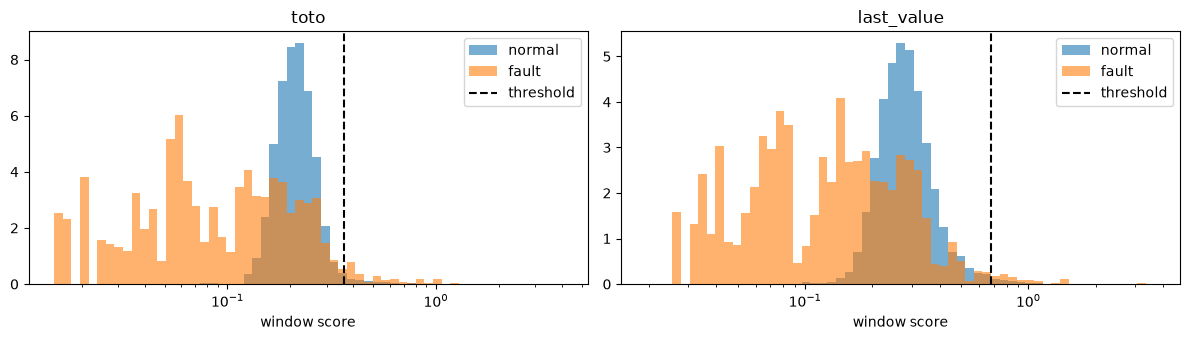

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for axis, name in zip(axes, ("toto", "last_value"), strict=True):
    run = load_run(OUTPUT_DIR / name)
    scores = np.load(OUTPUT_DIR / name / "scores.npz")["scores"]
    labels = np.array([run["expected"][p.scenario_id] for p in run["predictions"]])
    threshold = json.loads((OUTPUT_DIR / name / "detector.json").read_text())["threshold"]
    bins = np.logspace(np.log10(np.nanmin(scores[scores > 0])), np.log10(np.nanmax(scores)), 60)
    for label, title in ((0, "normal"), (1, "fault")):
        axis.hist(scores[labels == label], bins=bins, alpha=0.6, density=True, label=title)
    if threshold is not None:
        axis.axvline(threshold, color="black", linestyle="--", label="threshold")
    axis.set(xscale="log", title=name, xlabel="window score")
    axis.legend()
fig.tight_layout()

## Missed faults and false alarms by origin

In [4]:
errors = pd.concat([pd.DataFrame(json.loads((OUTPUT_DIR / name / "errors.json").read_text()))
                    .assign(detector=name) for name in ("toto", "last_value")])
errors.groupby(["detector", "origin", "rca_label"]).size().unstack("detector").fillna(0).astype(int)

detector                                             last_value  toto
origin    rca_label                                                  
normal    normal                                            175   222
real      Jamming                                            87    88
synthetic Antenna Failure                                    29    25
          Buffer Overflow (Gradual Buildup)                  21    20
          Co-Channel Interference (Mild)                     37    35
          Co-Channel Interference (Severe)                   15    10
          Doppler Shift (Severe)                              1     0
          Faulty Handover Algorithm (Too Frequent)            3     4
          Faulty RF Filters (Temporal)                        9     9
          High Network Congestion (Gradual Buildup)          11    10
          High Network Congestion (Sudden Spike)             16    10
          Resource Allocation Bugs                           17    16

## One forecast with the 10%-90% band

The band uses the 0.1 and 0.9 quantiles for display only; detection uses the median. Future values are never passed to the model.

<local-venv>
  from .autonotebook import tqdm as notebook_tqdm


<local-venv>
  warnings.warn(


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 549.17it/s]

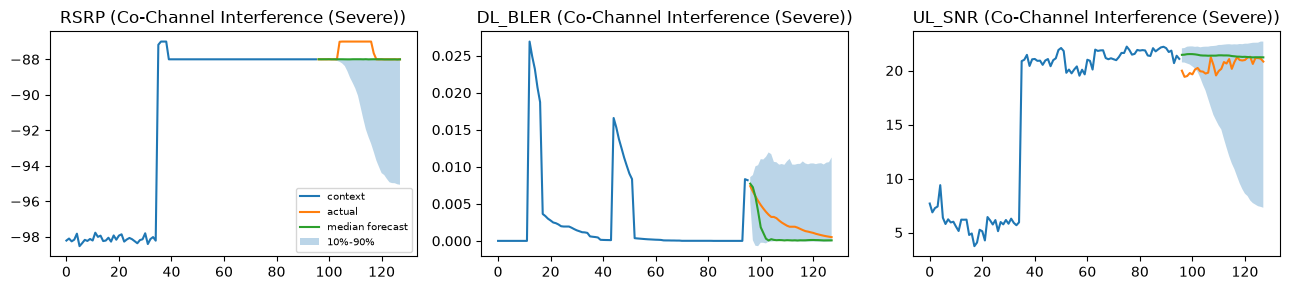

In [5]:
_, dev = split_data(DATASET, "detection", "dev")
members = DATASET.splits["membership"]
fault = next(i for i, sid in enumerate(dev.scenario_ids) if members[sid]["origin"] == "synthetic")
context, mask, target, _ = split_windows(window_arrays(dev.inputs[fault:fault + 1]))
model = load_forecaster(device="cpu")
with torch.inference_mode():
    quantiles = model.forecast({"target": torch.as_tensor(fill_context(context, mask), dtype=torch.float32),
                                "target_mask": torch.as_tensor(mask),
                                "series_ids": torch.zeros(1, 16, dtype=torch.long)},
                               horizon=HORIZON, decode_block_size=None, has_missing_values=True).numpy()
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharex=True)
for axis, name in zip(axes, ("RSRP", "DL_BLER", "UL_SNR"), strict=True):
    c = NUMERIC_CHANNELS.index(name)
    axis.plot(range(CONTEXT), context[0, c], label="context")
    axis.plot(range(CONTEXT, CONTEXT + HORIZON), target[0, c], label="actual")
    steps = range(CONTEXT, CONTEXT + HORIZON)
    axis.plot(steps, quantiles[QUANTILES.index(0.5), 0, c], label="median forecast")
    axis.fill_between(steps, quantiles[0, 0, c], quantiles[-1, 0, c], alpha=0.3, label="10%-90%")
    axis.set_title(f"{name} ({members[dev.scenario_ids[fault]]['rca_label']})")
axes[0].legend(fontsize=7)
fig.tight_layout()